In [81]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from fit_file import X_sq
from fit_classes import Data
import scipy.optimize as opt
import scipy.odr as odr

In [82]:
#lijst met alle getallen voor makkelijke data-inlading
getallen = np.arange(1, 213)
data_getallen = np.char.zfill(getallen.astype(str), 3)

In [89]:
#proef 1 - fit voor frequentie
#er wordt uitgegaan van 1 micros per tijdsinterval (pls god)

aan_box_matrix = np.loadtxt('data_107_212/data_107_000.txt', skiprows = 9).T
t = 1e-6 * (aan_box_matrix[0] - 1)
V1 = aan_box_matrix[1] #mV → fout is ook in mV

#fitten
def model_sinus(params, t):
    A, f, phi, C = params
    return A * np.sin(2 * np.pi * f * t + phi) + C

param_names = ['A', 'f', r'$\varphi$', 'C']

dt = np.full(len(t), 1e-9, float)
dV = np.full(len(V1), 1.953125, float)

X_sq(data = ((t, dt), (V1, dV)), param_names = param_names, initial_guess = (np.max(V1), 1013, 1, 1), model = model_sinus, PLOT = False)
#plt.scatter(t[:100], V1[:100]) #hieruit wordt fout gebaseerd (1.953125 mV)


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at      52.49082972     ;     68% CI = [     52.43055155,      52.55110791]
For parameter f        :     Minimum at    1031.14673413     ;     68% CI = [   1031.11576431,    1031.17770427]
For parameter $\varphi$ :     Minimum at      -1.06393150     ;     68% CI = [     -1.06506380,      -1.06279918]
For parameter C        :     Minimum at       0.76240415     ;     68% CI = [      0.72008205,       0.80472628]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        2880.12564276
Reduced χ² value       :     χ²_red           0.28812782
P-value                :     p-value          1.00000000
----------END---------------------------------------------------------------------------------------------------



In [84]:
#proef 2 - amplitude/positie
#inladen data (008 - 042)
x = np.arange(0, 17, 0.5)
alle_data_matrix = []
for i in data_getallen[7: 42]:
    if i != '025':
        alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])
    else:
        continue

data = Data(t, alle_data_matrix[0], dV, dt)
fit = data.fit(model_sinus, initial_guess = (np.max(alle_data_matrix[0]), 1028, 1))
print(fit)
##################################################
##alles_fitten
#for i in range(len(alle_data_matrix)):
#    if i < 21: #goedgedragende data
#        #data = Data(t, alle_data_matrix[i], dV, dt)
#        #fit = data.fit(model_sinus, initial_guess = (np.max(alle_data_matrix[i]), 1028, 1))
#        #print(fit)
#        #fit.show()
#        continue
#    else: #data verwijderen
#        data = Data(t, alle_data_matrix[i], dV, dt)
#        fit = data.fit(model_sinus, initial_guess = (np.max(alle_data_matrix[i]), 1028, 1))
#        print(i)
#        fit.show()
#        continue

#data = Data(t, alle_data_matrix[22], dV, dt)
#fit = data.fit(model_sinus, initial_guess = (np.max(alle_data_matrix[i]), 1028, 1))
#print(fit)
#fit.show()
#################################################


----------------------------------------------------------------------------------------------------------------
For parameter A        :     $    138.13128 \pm      0.05211 $
For parameter f        :     $   1028.20546 \pm      0.01019 $
For parameter phi      :     $     -0.98657 \pm      0.00037 $
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min      100997.77061237
Reduced χ² value       :     χ²_red          10.10280790
P-value                :     p-value          0.00000000
----------------------------------------------------------------------------------------------------------------



In [85]:
#Scipy odr testen
#def sinus(params, x):
#
#    return params[0] * np.sin(2 * np.pi * params[1] * x + params[2])
#
#model = odr.Model(sinus)
#data = odr.RealData(t * 1e3, alle_data_matrix[0], dt * 1e3, dV)
#initial_guess = [np.max(alle_data_matrix[0]), 1028, 1]
#my_odr = odr.ODR(data, model, beta0=initial_guess)
#output = my_odr.run()
#output.pprint()

[-1.39298516e+01  1.02750705e+03  2.03494866e+00  7.66003091e-01]
[0.06331635 0.2435859  0.00887815 0.04447124]
[1.22327780e-01 1.00979373e+03 6.66729704e-01 9.07613266e-01]
[  0.40181355 182.83729567   6.68383335   0.285161  ]
[-3.76436013e-01  1.00978661e+03  2.28547243e+00  7.01914491e-01]
[  1.53640039 223.20730426   8.03224349   1.08472157]
[-5.94581601e-01  1.01209118e+03  2.45569242e+00  7.81638637e-01]
[  2.86293188 260.52374562   9.42427403   2.01519362]
[-7.79096784e-01  1.01227163e+03  2.50615045e+00  7.57423729e-01]
[  3.95397392 274.133214     9.92754994   2.78179058]
[-9.96283159e-01  1.01410785e+03  2.51198434e+00  7.72294932e-01]
[  5.30428318 286.54560429  10.39652463   3.72838521]
[-1.38584854e+00  1.01277001e+03  2.47166808e+00  7.62845455e-01]
[  6.93448789 270.26304082   9.78605      4.87879775]
[-1.66054074e+00  1.01185142e+03  2.52442753e+00  6.92438300e-01]
[  8.06057573 262.29213725   9.49818895   5.67142997]
[-1.87169216e+00  1.01173594e+03  2.46356890e+00  5.

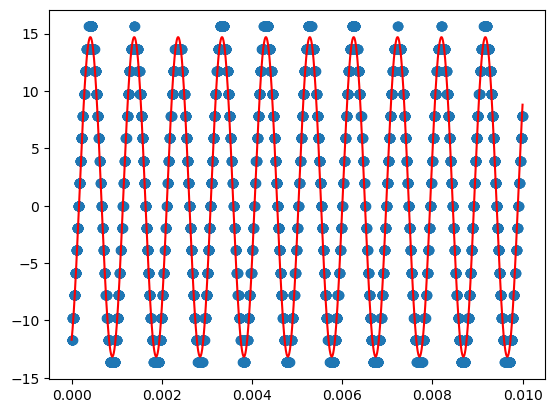

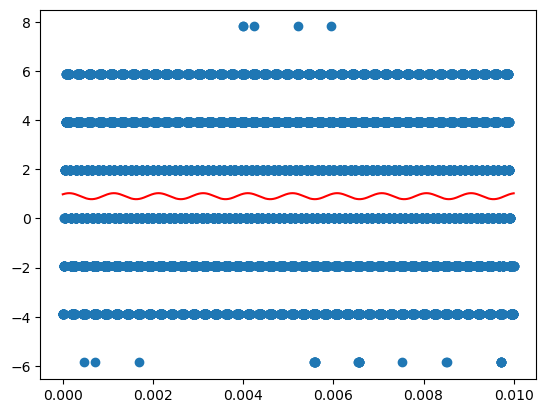

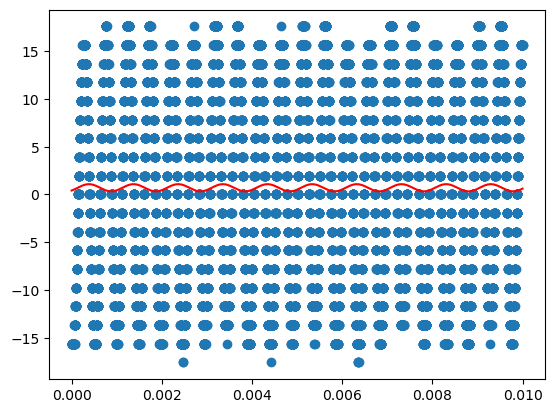

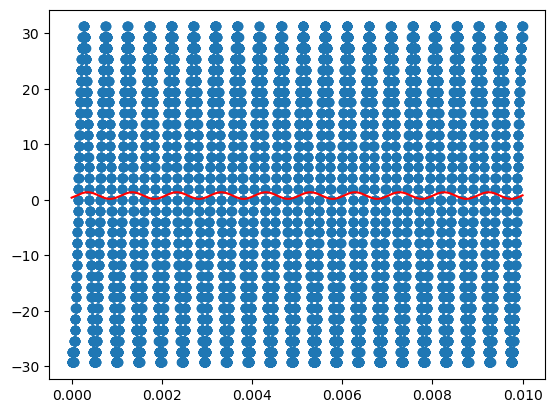

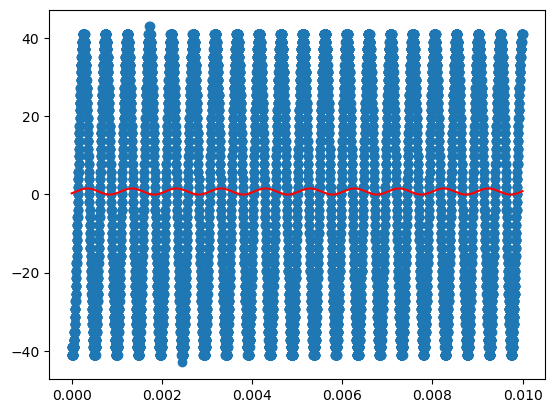

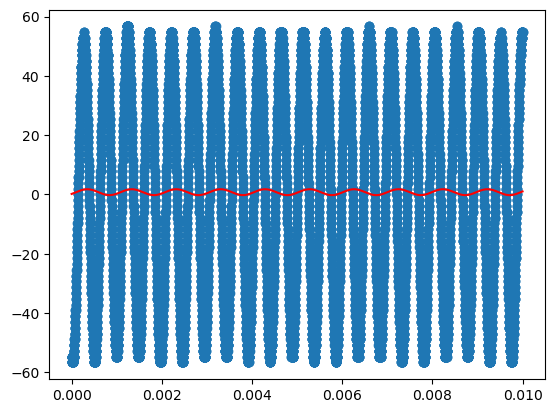

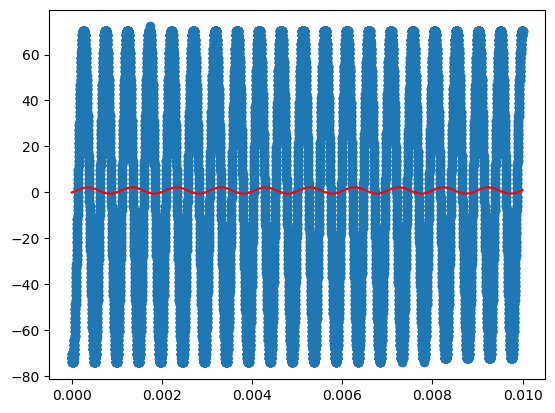

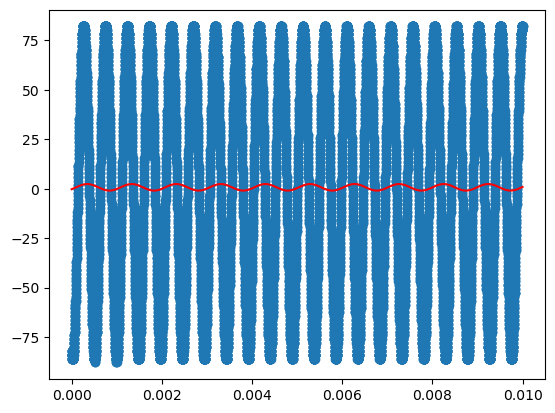

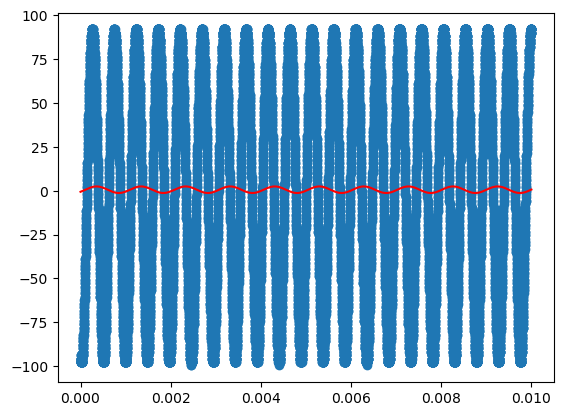

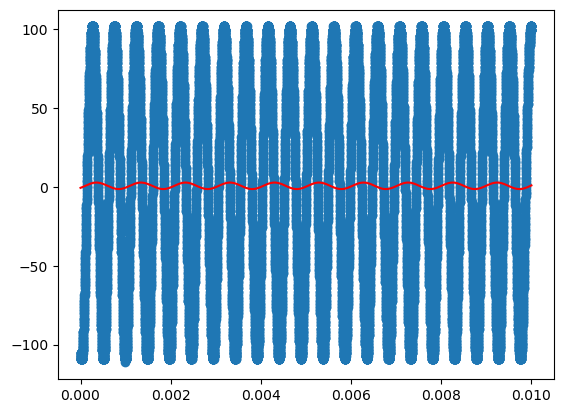

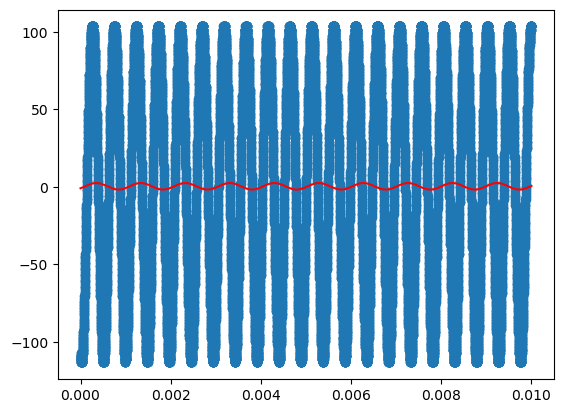

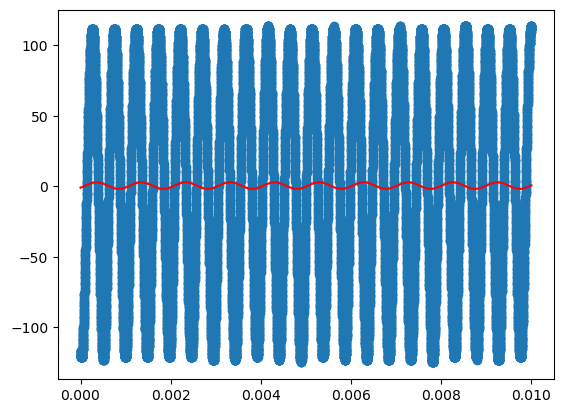

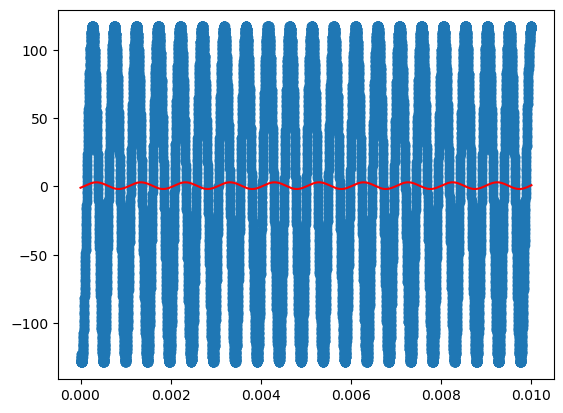

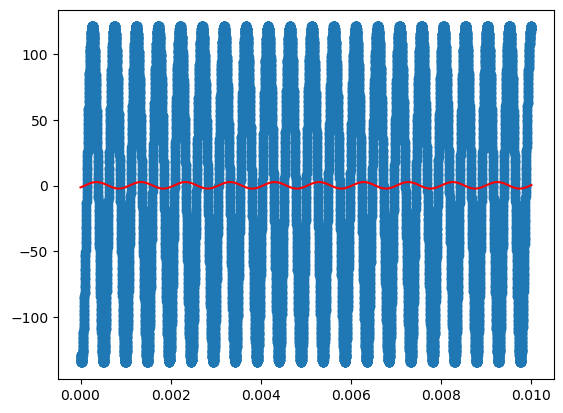

In [86]:
#Scipy curvefit testen
def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

counter = 0
for i in alle_data_matrix:
    counter += 1
    if counter < 21:
        #popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1028.20546, 1, 1], dV)
        #print(popt)
        #print(np.sqrt(np.diag(pcov)))
        #fig, ax = plt.subplots()
        #ax.scatter(t, i)
        #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
        continue
    else:

        # Snel de data groeperen/middelen (decimeren)
        # We nemen bijvoorbeeld het gemiddelde van elke 50 opeenvolgende punten
        aantal_samenvoegen = 100
        # Zorg dat de arrays netjes deelbaar zijn door 50
        limiet = len(t) - (len(t) % aantal_samenvoegen)
        t_kort = t[:limiet]
        y_kort = i[:limiet]
        # Bereken het gemiddelde per blokje van 50
        t_gemiddeld = t_kort.reshape(-1, aantal_samenvoegen).mean(axis=1)
        y_gemiddeld = y_kort.reshape(-1, aantal_samenvoegen).mean(axis=1)
        # Voer NU pas uw curve_fit uit op t_gemiddeld en y_gemiddeld
        # Omdat de ruis weg is, zal curve_fit de vorm van de sinus direct "zien".
        dV = np.full(len(y_gemiddeld), 1.953125, float)
        popt, pcov = opt.curve_fit(sinus, t_gemiddeld, y_gemiddeld, [np.max(i), 1028.20546, 1, 1], dV)
        print(popt)
        print(np.sqrt(np.diag(pcov)))
        fig, ax = plt.subplots()
        ax.scatter(t, i)
        ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')